# Section 3 Assignment: Mission Debrief, Restoring Mary's Reflexes


This assignment closes Section 3: Mary can see and remember, but her reflexes are clumsy, so you teach her to refine her actions directly with policy gradients. Plan for about 1 hour including training runs, 100 points, moderate difficulty. Use Python, NumPy, PyTorch, Gymnasium and Matplotlib. Stable-Baselines3 is allowed only for the comparison in Part 3, and no ready-made policy-gradient agents anywhere else. Each part ends with a short logbook question.


# Part 1: Reboot the Policy (REINFORCE on CartPole), 30 pts

Build a policy-gradient agent from scratch and train it on CartPole-v1.
Build a policy network (an MLP with one hidden layer of 64 units that outputs action probabilities) and sample actions with their log-probabilities. (4 pts)
Compute the discounted return-to-go for every step of an episode (γ = 0.99). (4 pts)
Implement REINFORCE and train it for 300 episodes on one seed. (8 pts)
Add a learned value baseline with normalized returns, then plot REINFORCE with and without the baseline on one figure. (8 pts)
Logbook: In 2-3 sentences, say why subtracting a baseline reduces variance without biasing the gradient. (6 pts)


In [3]:
# Import libraries and set random seeds

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import random

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

# Environment
env = gym.make("CartPole-v1")

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

print("State dimension:", state_dim)
print("Action dimension:", action_dim)

env.close()

Device: cpu
State dimension: 4
Action dimension: 2


In [4]:
# Build the policy network

class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim),
            nn.Softmax(dim=-1)
        )

    def forward(self, state):
        return self.network(state)

    def select_action(self, state):
        state = torch.as_tensor(
            state, dtype=torch.float32, device=device
        )

        action_probs = self.forward(state)

        distribution = torch.distributions.Categorical(
            probs=action_probs
        )

        action = distribution.sample()

        log_prob = distribution.log_prob(action)

        return action.item(), log_prob

In [ ]:
# class PolicyNetwork(nn.Module):
    def __init__(self, state_dim, action_dim):
        super(PolicyNetwork, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, action_dim),
            nn.Softmax(dim=-1)
        )

    def forward(self, state):
        return self.network(state)

    def select_action(self, state):
        state = torch.as_tensor(
            state, dtype=torch.float32, device=device
        )

        action_probs = self.forward(state)

        distribution = torch.distributions.Categorical(
            probs=action_probs
        )

        action = distribution.sample()

        log_prob = distribution.log_prob(action)

        return action.item(), log_prob

In [5]:
# Test the policy network

policy = PolicyNetwork(state_dim, action_dim).to(device)

env = gym.make("CartPole-v1")

state, info = env.reset(seed=SEED)

action, log_prob = policy.select_action(state)

print("State:", state)
print("Action:", action)
print("Log probability:", log_prob.item())

env.close()

State: [ 0.0273956  -0.00611216  0.03585979  0.0197368 ]
Action: 0
Log probability: -0.6264417171478271


In [6]:
# Compute discounted return-to-go

GAMMA = 0.99

def compute_returns(rewards, gamma=0.99):

    returns = []
    G = 0

    for reward in reversed(rewards):
        G = reward + gamma * G
        returns.insert(0, G)

    return torch.tensor(
        returns, dtype=torch.float32, device=device
    )

In [7]:
rewards = [1, 1, 1, 1]

returns = compute_returns(rewards, gamma=0.99)

print("Rewards:", rewards)
print("Discounted returns:", returns)

Rewards: [1, 1, 1, 1]
Discounted returns: tensor([3.9404, 2.9701, 1.9900, 1.0000])


In [8]:
# Implement REINFORCE without a baseline

def train_reinforce(
    episodes=300,
    gamma=0.99,
    lr=1e-3,
    seed=42
):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    env = gym.make("CartPole-v1")
    env.action_space.seed(seed)

    policy = PolicyNetwork(
        state_dim, action_dim
    ).to(device)

    optimizer = optim.Adam(
        policy.parameters(), lr=lr
    )

    episode_rewards = []

    for episode in range(episodes):

        state, info = env.reset(seed=seed + episode)

        log_probs = []
        rewards = []

        terminated = False
        truncated = False

        while not (terminated or truncated):

            action, log_prob = policy.select_action(state)

            next_state, reward, terminated, truncated, info = env.step(action)

            log_probs.append(log_prob)
            rewards.append(reward)

            state = next_state

        # Compute discounted returns
        returns = compute_returns(rewards, gamma)

        # Policy-gradient loss
        log_probs = torch.stack(log_probs)

        policy_loss = -(log_probs * returns).mean()

        # Update policy
        optimizer.zero_grad()

        policy_loss.backward()

        optimizer.step()

        episode_reward = sum(rewards)

        episode_rewards.append(episode_reward)

        if (episode + 1) % 20 == 0:
            print(
                f"Episode [{episode+1}/{episodes}] "
                f"Reward: {episode_reward:.1f} "
                f"Average(20): {np.mean(episode_rewards[-20:]):.2f}"
            )

    env.close()

    return policy, episode_rewards

In [9]:
# Train REINFORCE

reinforce_policy, reinforce_rewards = train_reinforce(
    episodes=300,
    gamma=0.99,
    lr=1e-3,
    seed=SEED
)

Episode [20/300] Reward: 12.0 Average(20): 21.50
Episode [40/300] Reward: 15.0 Average(20): 21.10
Episode [60/300] Reward: 10.0 Average(20): 18.60
Episode [80/300] Reward: 13.0 Average(20): 18.95
Episode [100/300] Reward: 17.0 Average(20): 19.35
Episode [120/300] Reward: 19.0 Average(20): 18.45
Episode [140/300] Reward: 25.0 Average(20): 19.00
Episode [160/300] Reward: 10.0 Average(20): 17.50
Episode [180/300] Reward: 8.0 Average(20): 18.30
Episode [200/300] Reward: 11.0 Average(20): 16.45
Episode [220/300] Reward: 11.0 Average(20): 17.95
Episode [240/300] Reward: 54.0 Average(20): 21.35
Episode [260/300] Reward: 35.0 Average(20): 24.55
Episode [280/300] Reward: 31.0 Average(20): 19.50
Episode [300/300] Reward: 11.0 Average(20): 24.30


In [10]:
# Add a learned value baseline

# Build the value network
class ValueNetwork(nn.Module):
    def __init__(self, state_dim):
        super(ValueNetwork, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )

    def forward(self, state):
        return self.network(state).squeeze(-1)

# Train REINFORCE with a baseline

def train_reinforce_baseline(
    episodes=300,
    gamma=0.99,
    policy_lr=1e-3,
    value_lr=1e-3,
    seed=42
):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    env = gym.make("CartPole-v1")
    env.action_space.seed(seed)

    policy = PolicyNetwork(
        state_dim, action_dim
    ).to(device)

    value_network = ValueNetwork(
        state_dim
    ).to(device)

    policy_optimizer = optim.Adam(
        policy.parameters(), lr=policy_lr
    )

    value_optimizer = optim.Adam(
        value_network.parameters(), lr=value_lr
    )

    episode_rewards = []

    for episode in range(episodes):

        state, info = env.reset(seed=seed + episode)

        states = []
        log_probs = []
        rewards = []

        terminated = False
        truncated = False

        while not (terminated or truncated):

            states.append(state.copy())

            action, log_prob = policy.select_action(state)

            next_state, reward, terminated, truncated, info = env.step(action)

            log_probs.append(log_prob)
            rewards.append(reward)

            state = next_state

        # Convert states to tensor
        states = torch.as_tensor(
            np.array(states),
            dtype=torch.float32,
            device=device
        )

        # Discounted returns
        returns = compute_returns(rewards, gamma)

        # Normalize returns
        returns = (
            returns - returns.mean()
        ) / (returns.std(unbiased=False) + 1e-8)

        # Predicted state values
        values = value_network(states)

        # Compute advantage
        advantages = returns - values.detach()

        # Policy loss
        log_probs = torch.stack(log_probs)

        policy_loss = -(
            log_probs * advantages
        ).mean()

        # Value loss
        value_loss = nn.functional.mse_loss(
            values, returns
        )

        # Update policy
        policy_optimizer.zero_grad()

        policy_loss.backward()

        policy_optimizer.step()

        # Update value network
        value_optimizer.zero_grad()

        value_loss.backward()

        value_optimizer.step()

        episode_reward = sum(rewards)

        episode_rewards.append(episode_reward)

        if (episode + 1) % 20 == 0:
            print(
                f"Episode [{episode+1}/{episodes}] "
                f"Reward: {episode_reward:.1f} "
                f"Average(20): {np.mean(episode_rewards[-20:]):.2f}"
            )

    env.close()

    return policy, value_network, episode_rewards

baseline_policy, value_network, baseline_rewards = train_reinforce_baseline(
    episodes=300,
    gamma=0.99,
    policy_lr=1e-3,
    value_lr=1e-3,
    seed=SEED
)

Episode [20/300] Reward: 12.0 Average(20): 26.35
Episode [40/300] Reward: 11.0 Average(20): 21.15
Episode [60/300] Reward: 29.0 Average(20): 24.35
Episode [80/300] Reward: 41.0 Average(20): 22.10
Episode [100/300] Reward: 20.0 Average(20): 23.75
Episode [120/300] Reward: 24.0 Average(20): 27.40
Episode [140/300] Reward: 94.0 Average(20): 37.85
Episode [160/300] Reward: 28.0 Average(20): 32.80
Episode [180/300] Reward: 35.0 Average(20): 40.35
Episode [200/300] Reward: 41.0 Average(20): 34.95
Episode [220/300] Reward: 32.0 Average(20): 44.60
Episode [240/300] Reward: 82.0 Average(20): 50.00
Episode [260/300] Reward: 96.0 Average(20): 54.60
Episode [280/300] Reward: 21.0 Average(20): 53.85
Episode [300/300] Reward: 58.0 Average(20): 50.75


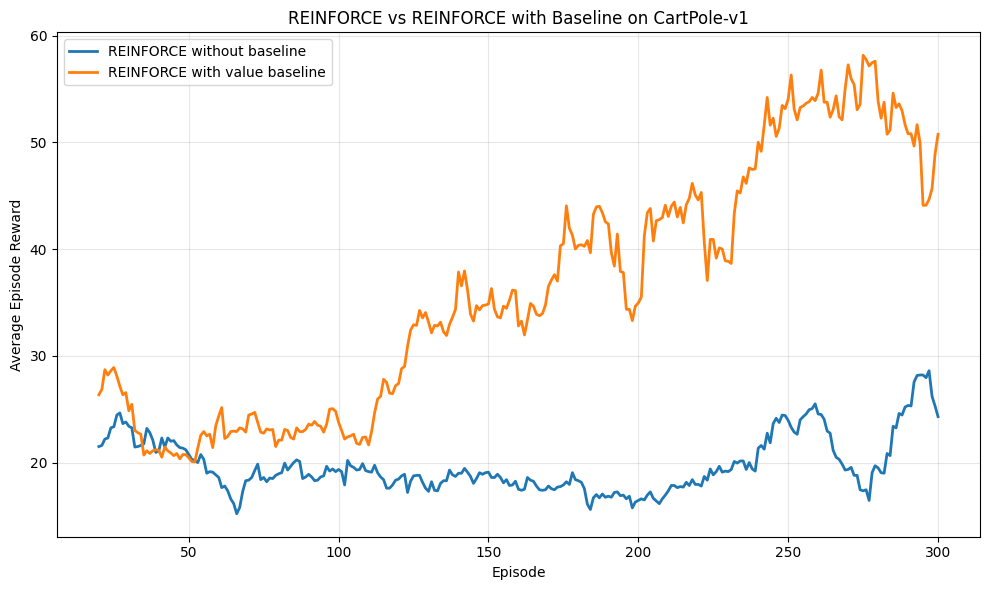

In [11]:
# Plot REINFORCE with and without baseline

def moving_average(rewards, window=20):
    return np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )


window = 20

reinforce_smooth = moving_average(
    reinforce_rewards, window
)

baseline_smooth = moving_average(
    baseline_rewards, window
)

episodes_axis = np.arange(
    window, len(reinforce_rewards) + 1
)

plt.figure(figsize=(10, 6))

plt.plot(
    episodes_axis,
    reinforce_smooth,
    label="REINFORCE without baseline",
    linewidth=2
)

plt.plot(
    episodes_axis,
    baseline_smooth,
    label="REINFORCE with value baseline",
    linewidth=2
)

plt.xlabel("Episode")
plt.ylabel("Average Episode Reward")
plt.title("REINFORCE vs REINFORCE with Baseline on CartPole-v1")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

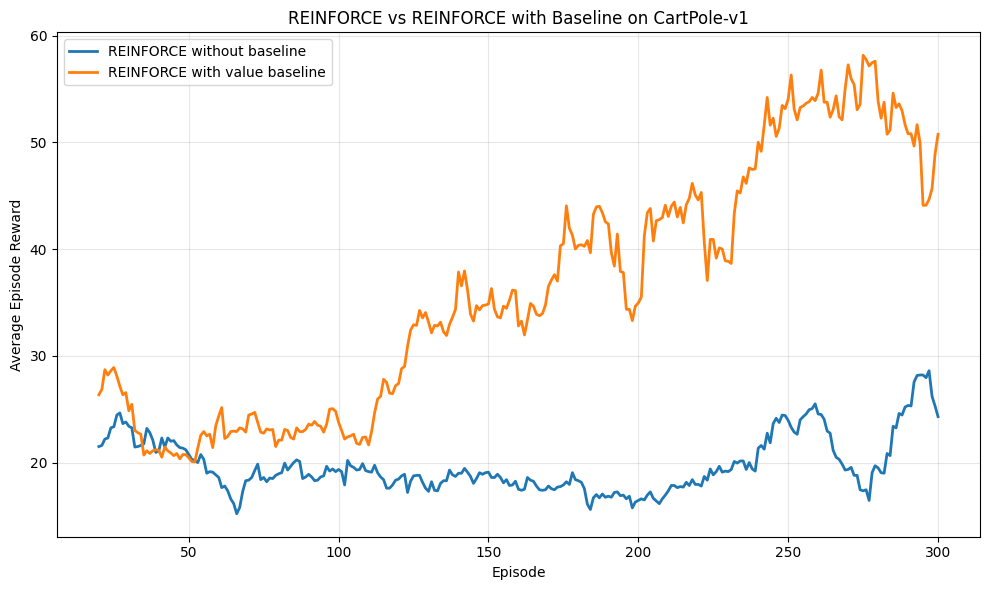

In [12]:
def moving_average(rewards, window=20):
    return np.convolve(
        rewards,
        np.ones(window) / window,
        mode="valid"
    )


window = 20

reinforce_smooth = moving_average(
    reinforce_rewards, window
)

baseline_smooth = moving_average(
    baseline_rewards, window
)

episodes_axis = np.arange(
    window, len(reinforce_rewards) + 1
)

plt.figure(figsize=(10, 6))

plt.plot(
    episodes_axis,
    reinforce_smooth,
    label="REINFORCE without baseline",
    linewidth=2
)

plt.plot(
    episodes_axis,
    baseline_smooth,
    label="REINFORCE with value baseline",
    linewidth=2
)

plt.xlabel("Episode")
plt.ylabel("Average Episode Reward")
plt.title("REINFORCE vs REINFORCE with Baseline on CartPole-v1")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Subtracting a state-dependent baseline reduces the variance of policy-gradient estimates by removing the component of the return that is predictable from the current state, allowing the agent to focus on actions that perform better or worse than expected. It does not introduce bias because the expected score-function gradient multiplied by an action-independent baseline is zero. This generally makes policy-gradient updates more stable and can improve learning efficiency.

# Part 2: Actor-Critic Reflexes (GAE, A2C and PPO), 40 pts

Build one actor-critic agent on CartPole-v1 with a single environment.
Build an actor-critic network with a policy head and a value head. (4 pts)
Implement GAE(λ) for a rollout (γ = 0.99, λ = 0.95), handling terminal states correctly. (10 pts)
Implement PPO: store the old log-probabilities, then run 4 epochs of minibatch updates with the clipped objective (ε = 0.2), plus a value loss and an entropy bonus. (14 pts)
Train for 50,000 environment steps on one seed, then train again with 1 epoch per batch and no clipping, which gives an A2C-style update. Plot both on one figure. (8 pts)
Logbook: In 2-3 sentences, say what the clipping prevents. (4 pts)


In [13]:
# Import libraries and set random seeds

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import random

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

env = gym.make("CartPole-v1")

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n

print("State dimension:", state_dim)
print("Action dimension:", action_dim)

env.close()

Device: cpu
State dimension: 4
Action dimension: 2


In [14]:
# Build Actor-Critic Network

class ActorCritic(nn.Module):

    def __init__(self, state_dim, action_dim):
        super(ActorCritic, self).__init__()

        # Shared feature extractor
        self.shared = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh()
        )

        # Actor: action logits
        self.actor = nn.Linear(64, action_dim)

        # Critic: state value
        self.critic = nn.Linear(64, 1)

    def forward(self, state):

        features = self.shared(state)

        action_logits = self.actor(features)

        state_value = self.critic(features).squeeze(-1)

        return action_logits, state_value

    def get_action(self, state):

        state = torch.as_tensor(
            state,
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():

            logits, value = self.forward(state)

            distribution = torch.distributions.Categorical(
                logits=logits
            )

            action = distribution.sample()

            log_prob = distribution.log_prob(action)

        return (
            action.item(),
            log_prob.item(),
            value.item()
        )

    def evaluate_actions(self, states, actions):

        logits, values = self.forward(states)

        distribution = torch.distributions.Categorical(
            logits=logits
        )

        log_probs = distribution.log_prob(actions)

        entropy = distribution.entropy()

        return log_probs, values, entropy

In [15]:
# Test the network

model = ActorCritic(state_dim, action_dim).to(device)

env = gym.make("CartPole-v1")

state, info = env.reset(seed=SEED)

action, log_prob, value = model.get_action(state)

print("Action:", action)
print("Log probability:", log_prob)
print("Estimated state value:", value)

env.close()

Action: 1
Log probability: -0.8827923536300659
Estimated state value: -0.20431961119174957


In [16]:
# Implement Generalized Advantage Estimation — GAE(λ)

# Implement GAE

def compute_gae(
    rewards,
    values,
    next_values,
    terminated,
    episode_ends,
    gamma=0.99,
    gae_lambda=0.95
):

    advantages = np.zeros(
        len(rewards),
        dtype=np.float32
    )

    last_gae = 0.0

    for t in reversed(range(len(rewards))):

        # Bootstrap for non-terminal transitions
        bootstrap_mask = 1.0 - float(terminated[t])

        # Stop recursion at any episode boundary
        continuation_mask = 1.0 - float(episode_ends[t])

        delta = (
            rewards[t]
            + gamma * bootstrap_mask * next_values[t]
            - values[t]
        )

        last_gae = (
            delta
            + gamma
            * gae_lambda
            * continuation_mask
            * last_gae
        )

        advantages[t] = last_gae

    returns = advantages + np.asarray(
        values, dtype=np.float32
    )

    return advantages, returns

# Test GAE

rewards = [1, 1, 1, 1]

values = [0.5, 0.6, 0.7, 0.8]

next_values = [0.6, 0.7, 0.8, 0.0]

terminated = [False, False, False, True]

episode_ends = [False, False, False, True]

advantages, returns = compute_gae(
    rewards,
    values,
    next_values,
    terminated,
    episode_ends,
    gamma=0.99,
    gae_lambda=0.95
)

print("Advantages:", advantages)
print("Returns:", returns)

Advantages: [3.2542665 2.2969341 1.2801    0.2      ]
Returns: [3.7542665 2.896934  1.9800999 1.       ]


In [17]:
# Collect Rollouts

def collect_rollout(
    env,
    model,
    state,
    rollout_steps,
    episode_reward,
    episode_rewards
):

    states = []
    actions = []
    rewards = []
    log_probs = []
    values = []
    next_values = []
    terminated_flags = []
    episode_end_flags = []

    for step in range(rollout_steps):

        action, log_prob, value = model.get_action(state)

        next_state, reward, terminated, truncated, info = env.step(
            action
        )

        done = terminated or truncated

        # Estimate value of the actual next observation
        with torch.no_grad():

            next_state_tensor = torch.as_tensor(
                next_state,
                dtype=torch.float32,
                device=device
            )

            _, next_value = model(next_state_tensor)

            next_value = next_value.item()

        states.append(state.copy())
        actions.append(action)
        rewards.append(reward)
        log_probs.append(log_prob)
        values.append(value)
        next_values.append(next_value)
        terminated_flags.append(terminated)
        episode_end_flags.append(done)

        episode_reward += reward

        if done:

            episode_rewards.append(episode_reward)

            episode_reward = 0.0

            state, info = env.reset()

        else:
            state = next_state

    rollout = {
        "states": np.asarray(states, dtype=np.float32),
        "actions": np.asarray(actions, dtype=np.int64),
        "rewards": np.asarray(rewards, dtype=np.float32),
        "log_probs": np.asarray(log_probs, dtype=np.float32),
        "values": np.asarray(values, dtype=np.float32),
        "next_values": np.asarray(next_values, dtype=np.float32),
        "terminated": np.asarray(terminated_flags, dtype=bool),
        "episode_ends": np.asarray(episode_end_flags, dtype=bool)
    }

    return rollout, state, episode_reward



In [18]:
# Implement PPO

# Implement the PPO update

def update_actor_critic(
    model,
    optimizer,
    rollout,
    advantages,
    returns,
    update_epochs=4,
    minibatch_size=64,
    clip_epsilon=0.2,
    value_coef=0.5,
    entropy_coef=0.01,
    use_clipping=True
):

    states = torch.as_tensor(
        rollout["states"],
        dtype=torch.float32,
        device=device
    )

    actions = torch.as_tensor(
        rollout["actions"],
        dtype=torch.long,
        device=device
    )

    old_log_probs = torch.as_tensor(
        rollout["log_probs"],
        dtype=torch.float32,
        device=device
    )

    advantages = torch.as_tensor(
        advantages,
        dtype=torch.float32,
        device=device
    )

    returns = torch.as_tensor(
        returns,
        dtype=torch.float32,
        device=device
    )

    batch_size = len(states)

    for epoch in range(update_epochs):

        indices = np.random.permutation(batch_size)

        for start in range(0, batch_size, minibatch_size):

            end = start + minibatch_size

            mb_indices = indices[start:end]

            mb_states = states[mb_indices]
            mb_actions = actions[mb_indices]
            mb_old_log_probs = old_log_probs[mb_indices]
            mb_advantages = advantages[mb_indices]
            mb_returns = returns[mb_indices]

            # Normalize advantages per minibatch
            mb_advantages = (
                mb_advantages - mb_advantages.mean()
            ) / (
                mb_advantages.std(unbiased=False) + 1e-8
            )

            # Evaluate actions using current policy
            new_log_probs, values, entropy = (
                model.evaluate_actions(
                    mb_states,
                    mb_actions
                )
            )

            # Probability ratio
            ratios = torch.exp(
                new_log_probs - mb_old_log_probs
            )

            # Policy objective
            surrogate1 = ratios * mb_advantages

            if use_clipping:

                surrogate2 = torch.clamp(
                    ratios,
                    1.0 - clip_epsilon,
                    1.0 + clip_epsilon
                ) * mb_advantages

                policy_loss = -torch.min(
                    surrogate1,
                    surrogate2
                ).mean()

            else:

                policy_loss = -surrogate1.mean()

            # Value loss
            value_loss = nn.functional.mse_loss(
                values,
                mb_returns
            )

            # Entropy bonus
            entropy_loss = entropy.mean()

            # Combined loss
            loss = (
                policy_loss
                + value_coef * value_loss
                - entropy_coef * entropy_loss
            )

            optimizer.zero_grad()

            loss.backward()

            # Gradient clipping
            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=0.5
            )

            optimizer.step()

In [19]:
# Train PPO and A2C-Style Agents

# Training function

def train_agent(
    algorithm="PPO",
    total_steps=50000,
    rollout_steps=256,
    gamma=0.99,
    gae_lambda=0.95,
    lr=3e-4,
    seed=42
):

    set_seed(seed)

    env = gym.make("CartPole-v1")

    env.action_space.seed(seed)

    state, info = env.reset(seed=seed)

    model = ActorCritic(
        state_dim,
        action_dim
    ).to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    episode_rewards = []
    episode_reward = 0.0

    total_env_steps = 0

    if algorithm == "PPO":

        update_epochs = 4
        use_clipping = True

    elif algorithm == "A2C":

        update_epochs = 1
        use_clipping = False

    else:
        raise ValueError("Algorithm must be PPO or A2C")

    reward_steps = []

    while total_env_steps < total_steps:

        steps_to_collect = min(
            rollout_steps,
            total_steps - total_env_steps
        )

        previous_episode_count = len(episode_rewards)

        # Collect rollout
        rollout, state, episode_reward = collect_rollout(
            env,
            model,
            state,
            steps_to_collect,
            episode_reward,
            episode_rewards
        )

        total_env_steps += steps_to_collect

        # GAE advantages and value targets
        advantages, returns = compute_gae(
            rollout["rewards"],
            rollout["values"],
            rollout["next_values"],
            rollout["terminated"],
            rollout["episode_ends"],
            gamma=gamma,
            gae_lambda=gae_lambda
        )

        # Update actor-critic network
        update_actor_critic(
            model=model,
            optimizer=optimizer,
            rollout=rollout,
            advantages=advantages,
            returns=returns,
            update_epochs=update_epochs,
            minibatch_size=64,
            clip_epsilon=0.2,
            value_coef=0.5,
            entropy_coef=0.01,
            use_clipping=use_clipping
        )

        # Record completed episodes against environment steps
        new_episodes = len(episode_rewards) - previous_episode_count

        if new_episodes > 0:
            reward_steps.extend(
                [total_env_steps] * new_episodes
            )

        if (
            total_env_steps % 5120 < steps_to_collect
            or total_env_steps == total_steps
        ):

            avg_reward = (
                np.mean(episode_rewards[-20:])
                if episode_rewards else 0.0
            )

            print(
                f"{algorithm} | "
                f"Steps: {total_env_steps}/{total_steps} | "
                f"Episodes: {len(episode_rewards)} | "
                f"Avg Reward (20): {avg_reward:.2f}"
            )

    env.close()

    return model, episode_rewards, reward_steps

In [20]:
# Train PPO for 50,000 Steps

ppo_model, ppo_rewards, ppo_steps = train_agent(
    algorithm="PPO",
    total_steps=50000,
    rollout_steps=256,
    gamma=0.99,
    gae_lambda=0.95,
    lr=3e-4,
    seed=SEED
)

PPO | Steps: 5120/50000 | Episodes: 181 | Avg Reward (20): 44.30
PPO | Steps: 10240/50000 | Episodes: 285 | Avg Reward (20): 52.00
PPO | Steps: 15360/50000 | Episodes: 373 | Avg Reward (20): 68.00
PPO | Steps: 20480/50000 | Episodes: 462 | Avg Reward (20): 44.65
PPO | Steps: 25600/50000 | Episodes: 543 | Avg Reward (20): 49.20
PPO | Steps: 30720/50000 | Episodes: 624 | Avg Reward (20): 52.85
PPO | Steps: 35840/50000 | Episodes: 684 | Avg Reward (20): 82.85
PPO | Steps: 40960/50000 | Episodes: 747 | Avg Reward (20): 78.45
PPO | Steps: 46080/50000 | Episodes: 806 | Avg Reward (20): 90.90
PPO | Steps: 50000/50000 | Episodes: 851 | Avg Reward (20): 85.80


In [21]:
# Train A2C-Style Agent for 50,000 Steps

a2c_model, a2c_rewards, a2c_steps = train_agent(
    algorithm="A2C",
    total_steps=50000,
    rollout_steps=256,
    gamma=0.99,
    gae_lambda=0.95,
    lr=3e-4,
    seed=SEED
)

A2C | Steps: 5120/50000 | Episodes: 230 | Avg Reward (20): 22.20
A2C | Steps: 10240/50000 | Episodes: 406 | Avg Reward (20): 34.80
A2C | Steps: 15360/50000 | Episodes: 553 | Avg Reward (20): 51.75
A2C | Steps: 20480/50000 | Episodes: 673 | Avg Reward (20): 51.05
A2C | Steps: 25600/50000 | Episodes: 784 | Avg Reward (20): 46.05
A2C | Steps: 30720/50000 | Episodes: 880 | Avg Reward (20): 67.20
A2C | Steps: 35840/50000 | Episodes: 967 | Avg Reward (20): 55.65
A2C | Steps: 40960/50000 | Episodes: 1068 | Avg Reward (20): 50.20
A2C | Steps: 46080/50000 | Episodes: 1155 | Avg Reward (20): 61.85
A2C | Steps: 50000/50000 | Episodes: 1225 | Avg Reward (20): 52.25


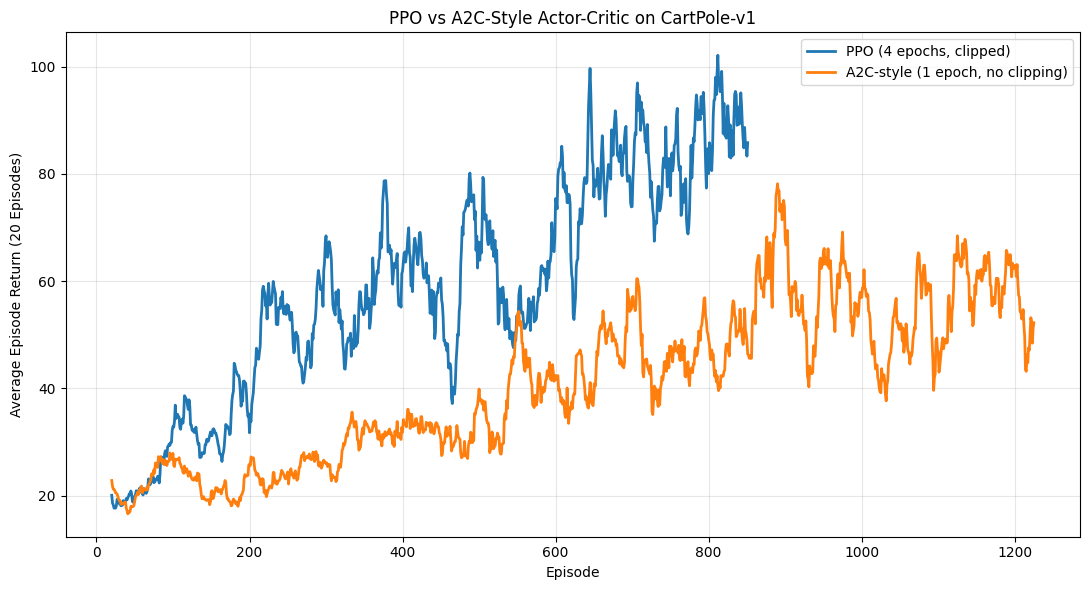

In [22]:
# Plot PPO vs A2C

def moving_average(values, window=20):

    values = np.asarray(values)

    if len(values) < window:
        return np.array([])

    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid"
    )


window = 20

ppo_smooth = moving_average(
    ppo_rewards,
    window
)

a2c_smooth = moving_average(
    a2c_rewards,
    window
)

plt.figure(figsize=(11, 6))

plt.plot(
    np.arange(window, len(ppo_rewards) + 1),
    ppo_smooth,
    label="PPO (4 epochs, clipped)",
    linewidth=2
)

plt.plot(
    np.arange(window, len(a2c_rewards) + 1),
    a2c_smooth,
    label="A2C-style (1 epoch, no clipping)",
    linewidth=2
)

plt.xlabel("Episode")
plt.ylabel("Average Episode Return (20 Episodes)")
plt.title("PPO vs A2C-Style Actor-Critic on CartPole-v1")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

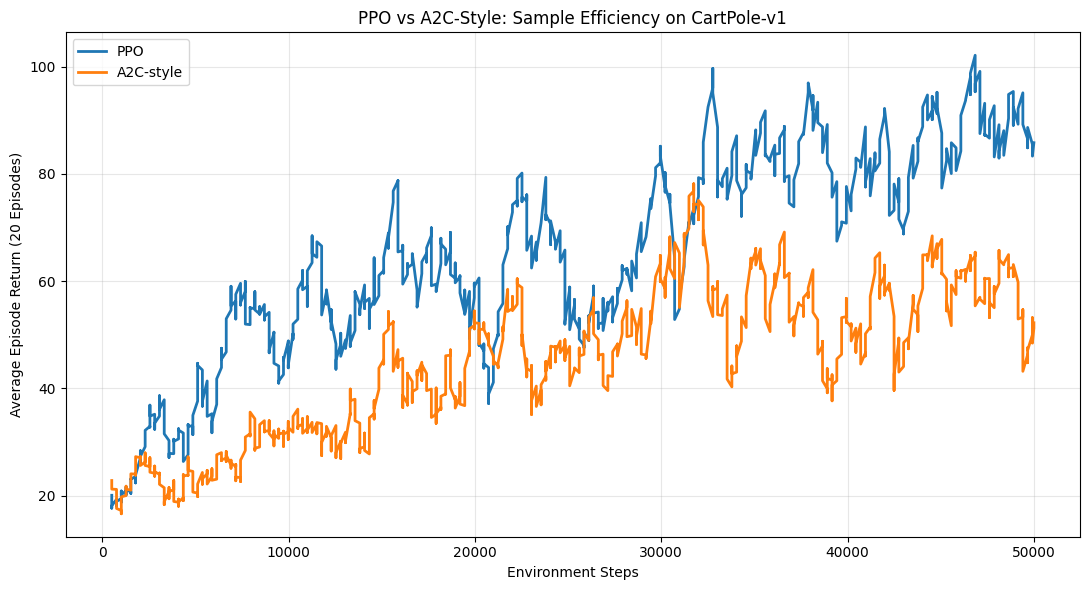

In [23]:
# Plot learning curves against environment steps

plt.figure(figsize=(11, 6))

if len(ppo_smooth) > 0:

    plt.plot(
        ppo_steps[window - 1:],
        ppo_smooth,
        label="PPO",
        linewidth=2
    )

if len(a2c_smooth) > 0:

    plt.plot(
        a2c_steps[window - 1:],
        a2c_smooth,
        label="A2C-style",
        linewidth=2
    )

plt.xlabel("Environment Steps")
plt.ylabel("Average Episode Return (20 Episodes)")
plt.title("PPO vs A2C-Style: Sample Efficiency on CartPole-v1")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [24]:
# Compare Final Performance

print("=" * 55)
print("FINAL PERFORMANCE COMPARISON")
print("=" * 55)

print(f"PPO total episodes: {len(ppo_rewards)}")
print(f"A2C total episodes: {len(a2c_rewards)}")

print("\nAverage reward over last 20 episodes:")

print(
    f"PPO: {np.mean(ppo_rewards[-20:]):.2f}"
)

print(
    f"A2C-style: {np.mean(a2c_rewards[-20:]):.2f}"
)

print("\nMaximum episode reward:")

print(
    f"PPO: {np.max(ppo_rewards):.2f}"
)

print(
    f"A2C-style: {np.max(a2c_rewards):.2f}"
)

print("\nOverall average episode reward:")

print(
    f"PPO: {np.mean(ppo_rewards):.2f}"
)

print(
    f"A2C-style: {np.mean(a2c_rewards):.2f}"
)

FINAL PERFORMANCE COMPARISON
PPO total episodes: 851
A2C total episodes: 1225

Average reward over last 20 episodes:
PPO: 85.80
A2C-style: 52.25

Maximum episode reward:
PPO: 234.00
A2C-style: 206.00

Overall average episode reward:
PPO: 58.74
A2C-style: 40.81


PPO clipping prevents excessively large policy updates by limiting the benefit of changing an action's probability ratio beyond a specified range, typically [0.8, 1.2]. This reduces the risk of unstable learning caused by aggressive policy changes when the same rollout is reused for multiple optimization epochs. Clipping improves training stability, although it does not strictly guarantee that the updated policy remains within the clipping range.

# Part 3: Fine Control and Wrap-Up (Pendulum), 30 pts

Take your PPO to a continuous action space: Pendulum-v1, which takes one torque in [−2, 2].
Replace the categorical policy with a Gaussian policy: the network outputs the mean, a separate learned log-standard-deviation sets the spread, and the sampled action is clipped to [−2, 2] only when it is sent to the environment (keep the unclipped sample for the log-probability). (8 pts)
Train for 50,000 environment steps and plot the learning curve next to a random-policy baseline. You are not expected to solve Pendulum in this time. (8 pts)
Run Stable-Baselines3 SAC on Pendulum-v1 for 10,000 steps with default settings and report its average return next to yours. This is the only place SB3 is allowed. (6 pts)
Logbook: In 2-3 sentences, say why a Gaussian policy suits continuous actions and why SAC may learn faster than PPO here. (5 pts)
Wrap-up: In one sentence each, say what makes PPO on-policy and SAC off-policy. (3 pts)


In [28]:
# Import Libraries and Initialize Environment

import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import random

from torch.distributions import Normal
from stable_baselines3 import SAC

SEED = 42

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

env = gym.make("Pendulum-v1")

state_dim = env.observation_space.shape[0]
action_dim = env.action_space.shape[0]

action_low = env.action_space.low
action_high = env.action_space.high

print("Device:", device)
print("State dimension:", state_dim)
print("Action dimension:", action_dim)
print("Action lower bound:", action_low)
print("Action upper bound:", action_high)

env.close()

Device: cpu
State dimension: 3
Action dimension: 1
Action lower bound: [-2.]
Action upper bound: [2.]


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [29]:
# Build Gaussian Actor-Critic Network

class GaussianActorCritic(nn.Module):

    def __init__(self, state_dim, action_dim):
        super(GaussianActorCritic, self).__init__()

        # Shared feature extractor
        self.shared = nn.Sequential(
            nn.Linear(state_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 64),
            nn.Tanh()
        )

        # Actor head: Gaussian mean
        self.actor_mean = nn.Linear(64, action_dim)

        # Learned log-standard-deviation
        self.log_std = nn.Parameter(
            torch.ones(action_dim) * -0.5
        )

        # Critic head: state value
        self.critic = nn.Linear(64, 1)

    def forward(self, state):

        features = self.shared(state)

        mean = self.actor_mean(features)

        value = self.critic(features).squeeze(-1)

        std = torch.exp(self.log_std).expand_as(mean)

        return mean, std, value

    def get_action(self, state):

        state = torch.as_tensor(
            state,
            dtype=torch.float32,
            device=device
        )

        with torch.no_grad():

            mean, std, value = self.forward(state)

            distribution = Normal(mean, std)

            # Sample UNCLIPPED action
            action = distribution.sample()

            # Log probability of UNCLIPPED action
            log_prob = distribution.log_prob(action).sum(-1)

        return (
            action.cpu().numpy(),
            log_prob.item(),
            value.item()
        )

    def evaluate_actions(self, states, actions):

        mean, std, values = self.forward(states)

        distribution = Normal(mean, std)

        log_probs = distribution.log_prob(actions).sum(-1)

        entropy = distribution.entropy().sum(-1)

        return log_probs, values, entropy

In [30]:
# Test Gaussian Policy

model = GaussianActorCritic(
    state_dim,
    action_dim
).to(device)

env = gym.make("Pendulum-v1")

state, info = env.reset(seed=SEED)

action, log_prob, value = model.get_action(state)

clipped_action = np.clip(
    action,
    action_low,
    action_high
)

print("Unclipped action:", action)
print("Clipped action:", clipped_action)
print("Log probability:", log_prob)
print("Estimated value:", value)
print("Learned log std:", model.log_std.data)

env.close()

Unclipped action: [0.15045676]
Clipped action: [0.15045676]
Log probability: -0.4202232360839844
Estimated value: -0.10487210750579834
Learned log std: tensor([-0.5000])


In [31]:
# Implement GAE for Continuous PPO

def compute_gae(
    rewards,
    values,
    next_values,
    terminated,
    episode_ends,
    gamma=0.99,
    gae_lambda=0.95
):

    advantages = np.zeros(
        len(rewards),
        dtype=np.float32
    )

    last_gae = 0.0

    for t in reversed(range(len(rewards))):

        bootstrap_mask = 1.0 - float(terminated[t])

        continuation_mask = 1.0 - float(episode_ends[t])

        delta = (
            rewards[t]
            + gamma * bootstrap_mask * next_values[t]
            - values[t]
        )

        last_gae = (
            delta
            + gamma
            * gae_lambda
            * continuation_mask
            * last_gae
        )

        advantages[t] = last_gae

    returns = advantages + np.asarray(
        values,
        dtype=np.float32
    )

    return advantages, returns

In [32]:
# Collect Continuous-Action Rollouts

def collect_continuous_rollout(
    env,
    model,
    state,
    rollout_steps,
    episode_reward,
    episode_rewards
):

    states = []
    actions = []
    rewards = []
    log_probs = []
    values = []
    next_values = []
    terminated_flags = []
    episode_end_flags = []

    for step in range(rollout_steps):

        # Sample Gaussian action
        action, log_prob, value = model.get_action(state)

        # Clip only for environment interaction
        env_action = np.clip(
            action,
            env.action_space.low,
            env.action_space.high
        )

        next_state, reward, terminated, truncated, info = env.step(
            env_action
        )

        done = terminated or truncated

        # Estimate next-state value
        with torch.no_grad():

            next_state_tensor = torch.as_tensor(
                next_state,
                dtype=torch.float32,
                device=device
            )

            _, _, next_value = model(next_state_tensor)

            next_value = next_value.item()

        states.append(state.copy())

        # Store UNCLIPPED action
        actions.append(action.copy())

        rewards.append(reward)
        log_probs.append(log_prob)
        values.append(value)
        next_values.append(next_value)

        terminated_flags.append(terminated)
        episode_end_flags.append(done)

        episode_reward += reward

        if done:

            episode_rewards.append(episode_reward)

            episode_reward = 0.0

            state, info = env.reset()

        else:

            state = next_state

    rollout = {
        "states": np.asarray(states, dtype=np.float32),
        "actions": np.asarray(actions, dtype=np.float32),
        "rewards": np.asarray(rewards, dtype=np.float32),
        "log_probs": np.asarray(log_probs, dtype=np.float32),
        "values": np.asarray(values, dtype=np.float32),
        "next_values": np.asarray(next_values, dtype=np.float32),
        "terminated": np.asarray(terminated_flags, dtype=bool),
        "episode_ends": np.asarray(episode_end_flags, dtype=bool)
    }

    return rollout, state, episode_reward

In [33]:
# Implement Continuous PPO Update

def update_continuous_ppo(
    model,
    optimizer,
    rollout,
    advantages,
    returns,
    update_epochs=4,
    minibatch_size=64,
    clip_epsilon=0.2,
    value_coef=0.5,
    entropy_coef=0.01
):

    states = torch.as_tensor(
        rollout["states"],
        dtype=torch.float32,
        device=device
    )

    actions = torch.as_tensor(
        rollout["actions"],
        dtype=torch.float32,
        device=device
    )

    old_log_probs = torch.as_tensor(
        rollout["log_probs"],
        dtype=torch.float32,
        device=device
    )

    advantages = torch.as_tensor(
        advantages,
        dtype=torch.float32,
        device=device
    )

    returns = torch.as_tensor(
        returns,
        dtype=torch.float32,
        device=device
    )

    batch_size = len(states)

    for epoch in range(update_epochs):

        indices = np.random.permutation(batch_size)

        for start in range(0, batch_size, minibatch_size):

            mb_indices = indices[
                start:start + minibatch_size
            ]

            mb_states = states[mb_indices]
            mb_actions = actions[mb_indices]

            mb_old_log_probs = old_log_probs[mb_indices]

            mb_advantages = advantages[mb_indices]
            mb_returns = returns[mb_indices]

            # Normalize advantages
            mb_advantages = (
                mb_advantages - mb_advantages.mean()
            ) / (
                mb_advantages.std(unbiased=False) + 1e-8
            )

            # Evaluate current Gaussian policy
            new_log_probs, values, entropy = (
                model.evaluate_actions(
                    mb_states,
                    mb_actions
                )
            )

            # PPO probability ratio
            ratios = torch.exp(
                new_log_probs - mb_old_log_probs
            )

            surrogate1 = ratios * mb_advantages

            surrogate2 = torch.clamp(
                ratios,
                1.0 - clip_epsilon,
                1.0 + clip_epsilon
            ) * mb_advantages

            policy_loss = -torch.min(
                surrogate1,
                surrogate2
            ).mean()

            value_loss = nn.functional.mse_loss(
                values,
                mb_returns
            )

            entropy_bonus = entropy.mean()

            loss = (
                policy_loss
                + value_coef * value_loss
                - entropy_coef * entropy_bonus
            )

            optimizer.zero_grad()

            loss.backward()

            nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=0.5
            )

            optimizer.step()

In [34]:
# Train PPO on Pendulum for 50,000 Steps

def train_continuous_ppo(
    total_steps=50000,
    rollout_steps=256,
    gamma=0.99,
    gae_lambda=0.95,
    lr=3e-4,
    seed=42
):

    set_seed(seed)

    env = gym.make("Pendulum-v1")

    env.action_space.seed(seed)

    state, info = env.reset(seed=seed)

    model = GaussianActorCritic(
        state_dim,
        action_dim
    ).to(device)

    optimizer = optim.Adam(
        model.parameters(),
        lr=lr
    )

    episode_rewards = []
    episode_reward = 0.0

    total_env_steps = 0

    while total_env_steps < total_steps:

        steps_to_collect = min(
            rollout_steps,
            total_steps - total_env_steps
        )

        rollout, state, episode_reward = (
            collect_continuous_rollout(
                env,
                model,
                state,
                steps_to_collect,
                episode_reward,
                episode_rewards
            )
        )

        total_env_steps += steps_to_collect

        # Compute GAE
        advantages, returns = compute_gae(
            rollout["rewards"],
            rollout["values"],
            rollout["next_values"],
            rollout["terminated"],
            rollout["episode_ends"],
            gamma=gamma,
            gae_lambda=gae_lambda
        )

        # PPO update
        update_continuous_ppo(
            model,
            optimizer,
            rollout,
            advantages,
            returns,
            update_epochs=4,
            minibatch_size=64,
            clip_epsilon=0.2,
            value_coef=0.5,
            entropy_coef=0.01
        )

        if (
            total_env_steps % 5000 < steps_to_collect
            or total_env_steps == total_steps
        ):

            avg_reward = (
                np.mean(episode_rewards[-10:])
                if episode_rewards else 0.0
            )

            print(
                f"PPO | "
                f"Steps: {total_env_steps}/{total_steps} | "
                f"Episodes: {len(episode_rewards)} | "
                f"Avg Reward (10): {avg_reward:.2f}"
            )

    env.close()

    return model, episode_rewards

In [35]:
# Train the Agent

ppo_model, ppo_rewards = train_continuous_ppo(
    total_steps=50000,
    rollout_steps=256,
    gamma=0.99,
    gae_lambda=0.95,
    lr=3e-4,
    seed=SEED
)

PPO | Steps: 5120/50000 | Episodes: 25 | Avg Reward (10): -1128.30
PPO | Steps: 10240/50000 | Episodes: 51 | Avg Reward (10): -1326.01
PPO | Steps: 15104/50000 | Episodes: 75 | Avg Reward (10): -1240.77
PPO | Steps: 20224/50000 | Episodes: 101 | Avg Reward (10): -1248.67
PPO | Steps: 25088/50000 | Episodes: 125 | Avg Reward (10): -1434.79
PPO | Steps: 30208/50000 | Episodes: 151 | Avg Reward (10): -1376.06
PPO | Steps: 35072/50000 | Episodes: 175 | Avg Reward (10): -1450.11
PPO | Steps: 40192/50000 | Episodes: 200 | Avg Reward (10): -1378.29
PPO | Steps: 45056/50000 | Episodes: 225 | Avg Reward (10): -1490.66
PPO | Steps: 50000/50000 | Episodes: 250 | Avg Reward (10): -1187.05


In [36]:
# Random-Policy Baseline

def evaluate_random_policy(
    episodes=250,
    seed=42
):

    env = gym.make("Pendulum-v1")

    env.action_space.seed(seed)

    episode_rewards = []

    for episode in range(episodes):

        state, info = env.reset(seed=seed + episode)

        terminated = False
        truncated = False

        total_reward = 0.0

        while not (terminated or truncated):

            action = env.action_space.sample()

            state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward

        episode_rewards.append(total_reward)

    env.close()

    return episode_rewards

In [37]:
# Run Random Baseline

random_rewards = evaluate_random_policy(
    episodes=250,
    seed=SEED
)

print(
    "Random policy average return:",
    np.mean(random_rewards)
)

Random policy average return: -1229.8990507023734


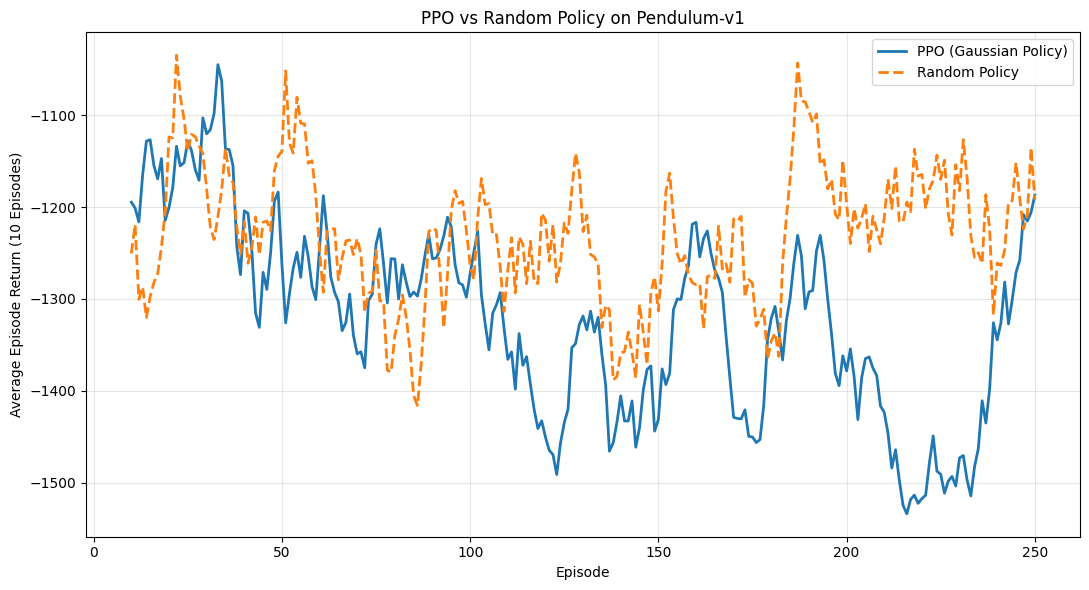

In [38]:
# Plot PPO vs Random Policy

def moving_average(values, window=10):

    values = np.asarray(values)

    return np.convolve(
        values,
        np.ones(window) / window,
        mode="valid"
    )


window = 10

ppo_smooth = moving_average(
    ppo_rewards,
    window
)

random_smooth = moving_average(
    random_rewards,
    window
)

plt.figure(figsize=(11, 6))

plt.plot(
    np.arange(window, len(ppo_rewards) + 1),
    ppo_smooth,
    label="PPO (Gaussian Policy)",
    linewidth=2
)

plt.plot(
    np.arange(window, len(random_rewards) + 1),
    random_smooth,
    label="Random Policy",
    linewidth=2,
    linestyle="--"
)

plt.xlabel("Episode")
plt.ylabel("Average Episode Return (10 Episodes)")
plt.title("PPO vs Random Policy on Pendulum-v1")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [39]:
# Evaluate Trained PPO

def evaluate_ppo(
    model,
    episodes=10,
    seed=1000
):

    env = gym.make("Pendulum-v1")

    episode_returns = []

    model.eval()

    for episode in range(episodes):

        state, info = env.reset(
            seed=seed + episode
        )

        terminated = False
        truncated = False

        total_reward = 0.0

        while not (terminated or truncated):

            state_tensor = torch.as_tensor(
                state,
                dtype=torch.float32,
                device=device
            )

            with torch.no_grad():

                mean, std, value = model(state_tensor)

                action = mean.cpu().numpy()

            action = np.clip(
                action,
                env.action_space.low,
                env.action_space.high
            )

            state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward

        episode_returns.append(total_reward)

    env.close()

    return episode_returns

In [40]:
# Evaluate PPO

ppo_eval_returns = evaluate_ppo(
    ppo_model,
    episodes=10,
    seed=1000
)

print("PPO evaluation returns:", ppo_eval_returns)

print(
    "PPO average evaluation return:",
    np.mean(ppo_eval_returns)
)

print(
    "PPO standard deviation:",
    np.std(ppo_eval_returns)
)

PPO evaluation returns: [np.float64(-1169.3378922892723), np.float64(-1171.4422079825863), np.float64(-993.1473260777195), np.float64(-1362.1803161442224), np.float64(-1812.4364731628596), np.float64(-1643.3981597275765), np.float64(-1087.4045694964855), np.float64(-1691.4935797629316), np.float64(-1418.9418398118978), np.float64(-1748.6375610570587)]
PPO average evaluation return: -1409.8419925512612
PPO standard deviation: 283.7908229418368


In [41]:
# Train Stable-Baselines3 SAC

from stable_baselines3 import SAC

sac_env = gym.make("Pendulum-v1")

sac_model = SAC(
    "MlpPolicy",
    sac_env,
    seed=SEED,
    verbose=1
)

sac_model.learn(
    total_timesteps=10000
)

sac_env.close()

Using cpu device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 200       |
|    ep_rew_mean     | -1.42e+03 |
| time/              |           |
|    episodes        | 4         |
|    fps             | 40        |
|    time_elapsed    | 19        |
|    total_timesteps | 800       |
| train/             |           |
|    actor_loss      | 21.8      |
|    critic_loss     | 0.27      |
|    ent_coef        | 0.813     |
|    ent_coef_loss   | -0.316    |
|    learning_rate   | 0.0003    |
|    n_updates       | 699       |
----------------------------------
----------------------------------
| rollout/           |           |
|    ep_len_mean     | 200       |
|    ep_rew_mean     | -1.43e+03 |
| time/              |           |
|    episodes        | 8         |
|    fps             | 33        |
|    time_elapsed    | 47        |
|    total_timesteps | 1600    

In [42]:
# Evaluate SAC

def evaluate_sac(
    model,
    episodes=10,
    seed=1000
):

    env = gym.make("Pendulum-v1")

    episode_returns = []

    for episode in range(episodes):

        state, info = env.reset(
            seed=seed + episode
        )

        terminated = False
        truncated = False

        total_reward = 0.0

        while not (terminated or truncated):

            action, _ = model.predict(
                state,
                deterministic=True
            )

            state, reward, terminated, truncated, info = (
                env.step(action)
            )

            total_reward += reward

        episode_returns.append(total_reward)

    env.close()

    return episode_returns

In [43]:
# Run Evaluation

sac_eval_returns = evaluate_sac(
    sac_model,
    episodes=10,
    seed=1000
)

print("SAC evaluation returns:", sac_eval_returns)

print(
    "SAC average evaluation return:",
    np.mean(sac_eval_returns)
)

print(
    "SAC standard deviation:",
    np.std(sac_eval_returns)
)

SAC evaluation returns: [np.float64(-0.7639901592759856), np.float64(-129.59079059936377), np.float64(-123.70742348966921), np.float64(-115.37955981817322), np.float64(-342.9022843297646), np.float64(-262.57608352588323), np.float64(-122.1881363591087), np.float64(-262.65412140724015), np.float64(-121.96988261043673), np.float64(-232.15427438212046)]
SAC average evaluation return: -171.3886546681036
SAC standard deviation: 95.33476827756544


In [44]:
# Compare PPO, SAC and Random Policy

random_eval_returns = evaluate_random_policy(
    episodes=10,
    seed=1000
)

print("=" * 60)
print("FINAL PERFORMANCE COMPARISON")
print("=" * 60)

print(
    f"PPO (50,000 steps): "
    f"{np.mean(ppo_eval_returns):.2f} "
    f"± {np.std(ppo_eval_returns):.2f}"
)

print(
    f"SAC (10,000 steps): "
    f"{np.mean(sac_eval_returns):.2f} "
    f"± {np.std(sac_eval_returns):.2f}"
)

print(
    f"Random Policy: "
    f"{np.mean(random_eval_returns):.2f} "
    f"± {np.std(random_eval_returns):.2f}"
)

FINAL PERFORMANCE COMPARISON
PPO (50,000 steps): -1409.84 ± 283.79
SAC (10,000 steps): -171.39 ± 95.33
Random Policy: -1302.89 ± 346.12


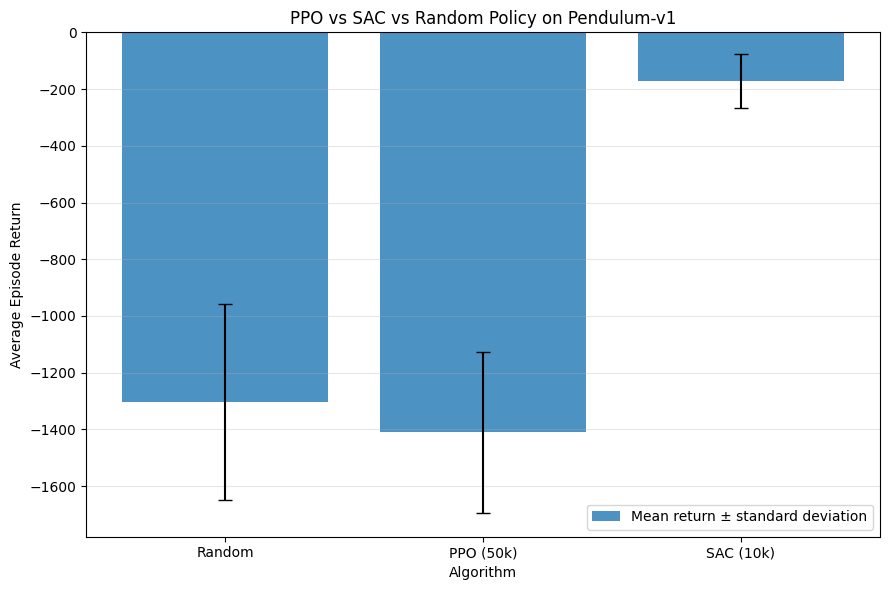

In [45]:
# Plot Final Performance Comparison

algorithms = [
    "Random",
    "PPO (50k)",
    "SAC (10k)"
]

mean_returns = [
    np.mean(random_eval_returns),
    np.mean(ppo_eval_returns),
    np.mean(sac_eval_returns)
]

std_returns = [
    np.std(random_eval_returns),
    np.std(ppo_eval_returns),
    np.std(sac_eval_returns)
]

plt.figure(figsize=(9, 6))

plt.bar(
    algorithms,
    mean_returns,
    yerr=std_returns,
    capsize=5,
    alpha=0.8,
    label="Mean return ± standard deviation"
)

plt.xlabel("Algorithm")
plt.ylabel("Average Episode Return")
plt.title("PPO vs SAC vs Random Policy on Pendulum-v1")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

A Gaussian policy is suitable for continuous action spaces because it represents actions using a continuous probability distribution whose mean and standard deviation control the selected torque and exploration. SAC may learn faster than PPO on Pendulum because it is an off-policy algorithm that reuses previous transitions from a replay buffer, improving sample efficiency. Additionally, SAC uses entropy regularization to encourage exploration and twin Q-networks to reduce overestimation bias.

# Deliverables, grading and hints

Submit one Jupyter notebook containing code, plots and logbook answers in markdown cells.

*   Fix random seeds so results are reproducible.
*   Label every plot with axes and a legend.

## Hints

*   Part 1: normalize returns across the batch, detach the baseline when you form the advantage, and train the value head with its own mean-squared-error loss.

*   Part 2: compute GAE backward through the rollout, bootstrap from the last observation's value when a rollout ends mid-episode, store log-probabilities from the sampling policy before any update, and normalize advantages per minibatch.

*   Part 3: Pendulum observations are cos θ, sin θ and angular velocity, and returns are negative, so a less negative return is better. Start the log-standard-deviation near −0.5 and use a small learning rate such as 3e-4.
